# Outcome Summary Statistics for the Project Proposal

This notebook downloads NYC TLC yellow taxi trips (October 2024 to September 2025) directly from the official source, samples 80,000 trips per month, removes invalid records, and computes summary statistics for the outcome variable, **trip duration in minutes**.

**How to run:** click **Runtime → Run all**. It takes about 5–10 minutes.

## 1. Setup

In [1]:
import pandas as pd

MONTHS = pd.period_range("2024-10", "2025-09", freq="M")
BASE = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{}.parquet"
COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
        "PULocationID", "DOLocationID", "passenger_count", "RatecodeID"]

## 2. Download and sample the trips

Each monthly file is read straight from the TLC website. Only trips whose pickup falls inside that month are kept, then 80,000 are sampled at random (`random_state=42` for reproducibility).

In [2]:
samples = []
for m in MONTHS:
    df = pd.read_parquet(BASE.format(m.strftime("%Y-%m")), columns=COLS)
    df = df[df["tpep_pickup_datetime"].dt.to_period("M") == m]
    samples.append(df.sample(n=min(80_000, len(df)), random_state=42))
    print(m, "loaded", len(df), "trips")

trips = pd.concat(samples, ignore_index=True)
print("Sampled trips:", len(trips))

2024-10 loaded 3833731 trips
2024-11 loaded 3646319 trips
2024-12 loaded 3668337 trips
2025-01 loaded 3475204 trips
2025-02 loaded 3577512 trips
2025-03 loaded 4145224 trips
2025-04 loaded 3970546 trips
2025-05 loaded 4591821 trips
2025-06 loaded 4322940 trips
2025-07 loaded 3898956 trips
2025-08 loaded 3574074 trips
2025-09 loaded 4251008 trips
Sampled trips: 960000


## 3. Create the outcome and remove invalid trips

Trip duration = drop-off time − pickup time, in minutes. Invalid records are removed: zero distance, durations under 1 minute or over 3 hours, and average speeds above 80 mph.

In [3]:
trips["duration_min"] = (trips["tpep_dropoff_datetime"]
                         - trips["tpep_pickup_datetime"]).dt.total_seconds() / 60

speed_mph = trips["trip_distance"] / (trips["duration_min"] / 60)
clean = trips[(trips["trip_distance"] > 0)
              & trips["duration_min"].between(1, 180)
              & (speed_mph <= 80)]
print("Removed as invalid:", len(trips) - len(clean), "trips")
print("Clean trips:", len(clean))

Removed as invalid: 35986 trips
Clean trips: 924014


## 4. Summary statistics (copy this table into the proposal)

In [4]:
d = clean["duration_min"]
summary = pd.Series({
    "Number of trips (n)": len(d),
    "Mean": d.mean(),
    "Standard deviation": d.std(),
    "Minimum": d.min(),
    "25th percentile": d.quantile(0.25),
    "Median": d.median(),
    "75th percentile": d.quantile(0.75),
    "90th percentile": d.quantile(0.90),
    "Maximum": d.max(),
}).round(2)
print(summary.to_string())

Number of trips (n)    924014.00
Mean                       17.00
Standard deviation         13.45
Minimum                     1.00
25th percentile             8.25
Median                     13.38
75th percentile            21.27
90th percentile            32.52
Maximum                   179.55


## 5. Distribution of trip duration (optional chart for the proposal)

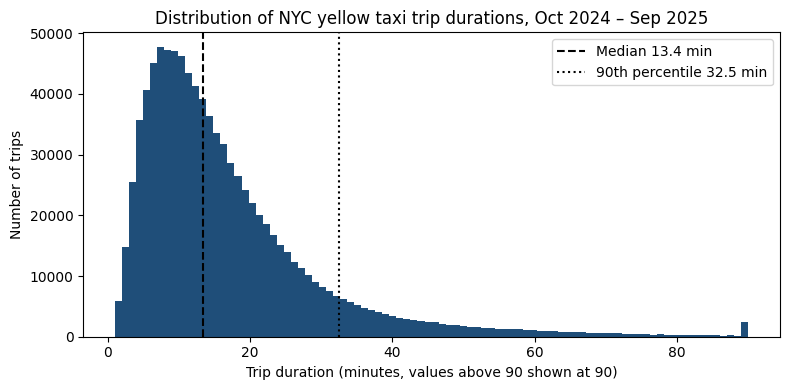

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(d.clip(upper=90), bins=90, color="#1F4E79")
ax.axvline(d.median(), color="black", linestyle="--", label=f"Median {d.median():.1f} min")
ax.axvline(d.quantile(0.9), color="black", linestyle=":", label=f"90th percentile {d.quantile(0.9):.1f} min")
ax.set_xlabel("Trip duration (minutes, values above 90 shown at 90)")
ax.set_ylabel("Number of trips")
ax.set_title("Distribution of NYC yellow taxi trip durations, Oct 2024 – Sep 2025")
ax.legend()
plt.tight_layout()
plt.show()